# 7. Sufficient statistics

**Cover and Thomas, Section 2.9.**

Let $\{f_\theta(x)\}$ be a family of distributions indexed by a parameter
$\theta$, let $X$ be a sample from one of them, and let $T(X)$ be any
statistic. Since $T$ is computed from $X$ alone,

$$\theta \to X \to T(X)$$

is a Markov chain, and the data-processing inequality of notebook 06 gives

$$I(\theta; T(X)) \;\le\; I(\theta; X).$$

**Definition.** $T(X)$ is **sufficient** for $\theta$ if $X$ is independent of
$\theta$ given $T(X)$, that is, if $\theta \to T(X) \to X$ is also a Markov
chain. This is exactly the condition for equality:

$$T \text{ sufficient} \iff I(\theta;X) = I(\theta;T(X)) \text{ for every distribution on } \theta .$$

**Definition.** $T$ is **minimal sufficient** if it is a function of every
other sufficient statistic $U$, that is, if
$\theta \to T(X) \to U(X) \to X$.

This notebook works out the first example of the book completely, by exact
enumeration: $n$ tosses of a coin with unknown bias $\theta$, for which
$T = \sum_i X_i$ is sufficient.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
import infotools as it

it.setup_plot_style()
rng = np.random.default_rng(7)

## 7.1 The set-up

To stay inside Chapter 2 we keep everything discrete: $\theta$ lives on a
finite grid and carries a prior. Mutual information between $\theta$ and the
data is then an ordinary discrete mutual information, computed from a table.

The joint distribution of $(\theta, X)$ is

$$p(\theta, x) = \pi(\theta)\; \theta^{k(x)} (1-\theta)^{\,n - k(x)},
\qquad k(x) = \text{number of ones in } x .$$

In [2]:
n = 8                                        # <-- number of coin tosses
theta_grid = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
prior = np.ones(len(theta_grid)) / len(theta_grid)     # uniform prior on the grid

sequences = np.array(list(product([0, 1], repeat=n)))  # all 2^n sequences
print("number of sequences:", len(sequences))


def joint_theta_x(theta_grid, prior, sequences):
    """Table J[t, s] = p(theta = theta_grid[t], X = sequences[s])."""
    k = sequences.sum(axis=1)                         # number of ones in each sequence
    n = sequences.shape[1]
    likelihood = (theta_grid[:, None] ** k[None, :]
                  * (1 - theta_grid[:, None]) ** (n - k[None, :]))
    return prior[:, None] * likelihood


J = joint_theta_x(theta_grid, prior, sequences)
print("shape of the joint table:", J.shape)
print("total probability:", J.sum())
print()
print(f"I(theta ; X) = {it.mutual_information(J):.6f} bits")
print(f"H(theta)     = {it.entropy(prior):.6f} bits")

number of sequences: 256
shape of the joint table: (9, 256)
total probability: 1.0

I(theta ; X) = 0.920996 bits
H(theta)     = 3.169925 bits


## 7.2 Applying a statistic

A statistic assigns to each sequence a value. To get the joint table of
$(\theta, T)$ we simply add up the columns that share the same value of $T$.

In [3]:
def apply_statistic(J, values):
    """Joint table of (theta, T) from the joint table of (theta, X).

    `values` gives, for each column of J, the value of the statistic. Columns
    with the same value are added together.
    """
    labels, inverse = np.unique(np.asarray(values), axis=0, return_inverse=True)
    out = np.zeros((J.shape[0], len(labels)))
    for s in range(J.shape[1]):
        out[:, inverse[s]] += J[:, s]
    return out, labels


# four statistics of the same data
T_total = sequences.sum(axis=1)                       # sum of all tosses: sufficient
T_first = sequences[:, 0]                             # the first toss only
T_half = sequences[:, :n//2].sum(axis=1)              # sum of the first half
T_pair = np.column_stack([sequences[:, 0::2].sum(axis=1),     # (odd sum, even sum)
                          sequences[:, 1::2].sum(axis=1)])

I_X = it.mutual_information(J)
results = {}
for name, values in [("X (the whole sample)", sequences),
                     ("T = sum of all tosses", T_total),
                     ("(odd sum, even sum)", T_pair),
                     ("sum of the first half", T_half),
                     ("the first toss only", T_first)]:
    table, labels = apply_statistic(J, values)
    results[name] = (it.mutual_information(table), len(labels))

print(f"{'statistic':28s} {'number of values':>17s} {'I(theta ; T)':>14s}")
for name, (I_T, n_vals) in results.items():
    print(f"{name:28s} {n_vals:>17d} {I_T:>14.6f}")

statistic                     number of values   I(theta ; T)
X (the whole sample)                       256       0.920996
T = sum of all tosses                        9       0.920996
(odd sum, even sum)                         25       0.920996
sum of the first half                        5       0.610167
the first toss only                          2       0.212630


Three things to read off that table.

* $T = \sum_i X_i$ has only $n+1 = 9$ values instead of $2^n = 256$, yet it
  carries **exactly** the same information about $\theta$ as the whole
  sample. It is sufficient.
* The pair (odd sum, even sum) is also sufficient. It has more values than
  $T$, so it keeps some information about $x$ that is irrelevant to $\theta$.
* The other two statistics throw away real information: their mutual
  information with $\theta$ is strictly smaller.

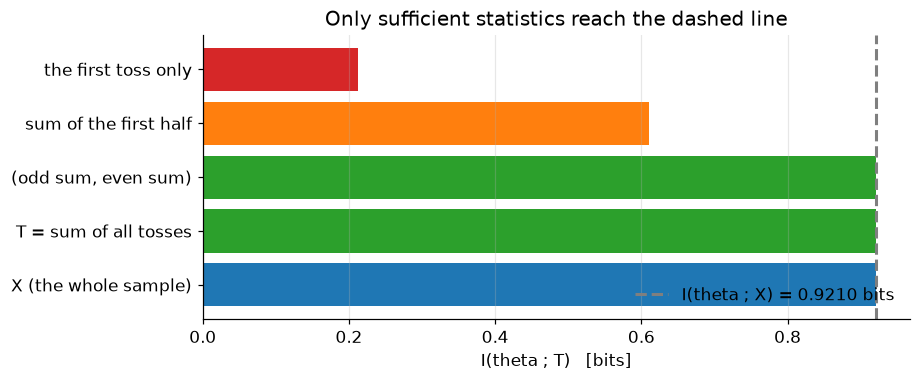

[PASS] I(theta ; sum) = I(theta ; X)
[PASS] I(theta ; (odd sum, even sum)) = I(theta ; X)
[PASS] I(theta ; first half sum) < I(theta ; X)
[PASS] I(theta ; first toss) < I(theta ; X)


True

In [4]:
names = list(results.keys())
I_values = [results[k][0] for k in names]

plt.figure(figsize=(8.5, 3.6))
bars = plt.barh(names, I_values,
                color=[it.COLORS["H"], it.COLORS["I"], it.COLORS["I"],
                       it.COLORS["cond"], it.COLORS["D"]])
plt.axvline(I_X, color=it.COLORS["bound"], linestyle="--",
            label=f"I(theta ; X) = {I_X:.4f} bits")
plt.xlabel("I(theta ; T)   [bits]")
plt.title("Only sufficient statistics reach the dashed line")
plt.legend(loc="lower right")
plt.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

it.check("I(theta ; sum) = I(theta ; X)",
         np.isclose(results["T = sum of all tosses"][0], I_X))
it.check("I(theta ; (odd sum, even sum)) = I(theta ; X)",
         np.isclose(results["(odd sum, even sum)"][0], I_X))
it.check("I(theta ; first half sum) < I(theta ; X)",
         results["sum of the first half"][0] < I_X - 1e-6)
it.check("I(theta ; first toss) < I(theta ; X)",
         results["the first toss only"][0] < I_X - 1e-6)

## 7.3 Why the sum is sufficient: equation (2.125)

The book's argument is that, given $\sum_i X_i = k$, all $\binom nk$
sequences with $k$ ones are equally likely **whatever $\theta$ is**:

$$\Pr\Big\{(X_1,\dots,X_n) = (x_1,\dots,x_n) \;\Big|\; \sum_i X_i = k\Big\}
= \begin{cases} 1/\binom nk & \text{if } \sum_i x_i = k,\\ 0 & \text{otherwise.}\end{cases}$$

The cell below checks this directly: for each $\theta$ on the grid and each
value $k$, it computes $p(x \mid \theta, T = k)$ and compares it with the
uniform distribution over the sequences having $k$ ones.

In [5]:
from math import comb

max_deviation = 0.0
for t, theta in enumerate(theta_grid):
    p_x_given_theta = theta ** T_total * (1 - theta) ** (n - T_total)
    for k in range(n + 1):
        in_group = (T_total == k)
        conditional = p_x_given_theta[in_group]
        conditional = conditional / conditional.sum()      # p(x | theta, T = k)
        uniform = np.ones(in_group.sum()) / comb(n, k)
        max_deviation = max(max_deviation, np.abs(conditional - uniform).max())

it.check("p(x | theta, T = k) is uniform and does not depend on theta",
         max_deviation < 1e-12, f"largest deviation: {max_deviation:.2e}")

print("\nThis is exactly the Markov chain  theta -> T(X) -> X.")
print("Once you know how many heads came up, the order tells you nothing more")
print("about the bias of the coin.")

[PASS] p(x | theta, T = k) is uniform and does not depend on theta   largest deviation: 1.39e-17

This is exactly the Markov chain  theta -> T(X) -> X.
Once you know how many heads came up, the order tells you nothing more
about the bias of the coin.


The same statement in information-theoretic form: $I(\theta; X \mid T) = 0$.

In [6]:
# Build the three-variable table p(theta, T, X). Since T is a function of X,
# the entry is nonzero only when T equals the value computed from x.
P3 = np.zeros((len(theta_grid), n + 1, len(sequences)))
for s in range(len(sequences)):
    P3[:, T_total[s], s] = J[:, s]


def H_of(P, axes):
    axes = list(axes)
    if len(axes) == 0:
        return 0.0
    drop = tuple(a for a in range(P.ndim) if a not in axes)
    return it.entropy(P.sum(axis=drop) if drop else P)


I_theta_X_given_T = (H_of(P3, [0, 1]) + H_of(P3, [1, 2])
                     - H_of(P3, [0, 1, 2]) - H_of(P3, [1]))
print(f"I(theta ; X | T) = {I_theta_X_given_T:.3e}")
it.check("I(theta ; X | T) = 0, so theta -> T -> X is a Markov chain",
         abs(I_theta_X_given_T) < 1e-9)

I(theta ; X | T) = 0.000e+00
[PASS] I(theta ; X | T) = 0, so theta -> T -> X is a Markov chain


True

## 7.4 Sufficiency does not depend on the prior

The definition asks for equality **for every distribution on $\theta$**. A
non-sufficient statistic fails for any prior that puts mass on more than one
value; a sufficient one succeeds for all of them. Let us try several priors.

In [7]:
priors = {
    "uniform": np.ones(len(theta_grid)) / len(theta_grid),
    "concentrated near 0.5": np.exp(-20 * (theta_grid - 0.5)**2),
    "two spikes at 0.2 and 0.8": np.array([0, 1, 0, 0, 0, 0, 0, 1, 0], float),
    "random": rng.dirichlet(np.ones(len(theta_grid))),
}

print(f"{'prior':28s} {'I(theta;X)':>12s} {'I(theta;T)':>12s} {'I(theta;X1)':>12s}")
for name, pi in priors.items():
    pi = pi / pi.sum()
    Jp = joint_theta_x(theta_grid, pi, sequences)
    I_full = it.mutual_information(Jp)
    I_sum = it.mutual_information(apply_statistic(Jp, T_total)[0])
    I_one = it.mutual_information(apply_statistic(Jp, T_first)[0])
    print(f"{name:28s} {I_full:>12.6f} {I_sum:>12.6f} {I_one:>12.6f}")
    it.check(f"  sum is sufficient under the {name} prior", np.isclose(I_full, I_sum))

prior                          I(theta;X)   I(theta;T)  I(theta;X1)
uniform                          0.920996     0.920996     0.212630
[PASS]   sum is sufficient under the uniform prior
concentrated near 0.5            0.447010     0.447010     0.073315
[PASS]   sum is sufficient under the concentrated near 0.5 prior
two spikes at 0.2 and 0.8        0.891804     0.891804     0.278072
[PASS]   sum is sufficient under the two spikes at 0.2 and 0.8 prior
random                           0.818998     0.818998     0.179885
[PASS]   sum is sufficient under the random prior


## 7.5 Minimal sufficiency

Both $T = \sum_i X_i$ and $U = (\text{odd sum}, \text{even sum})$ are
sufficient. But $T$ is a **function** of $U$ (add the two coordinates), while
$U$ is not a function of $T$. So $T$ compresses more, and the chain

$$\theta \to T(X) \to U(X) \to X$$

holds. The entropies make the difference visible.

In [8]:
table_T, _ = apply_statistic(J, T_total)
table_U, _ = apply_statistic(J, T_pair)

H_T = it.entropy(table_T.sum(axis=0))
H_U = it.entropy(table_U.sum(axis=0))
H_X = it.entropy(J.sum(axis=0))

print(f"H(X)           = {H_X:.6f} bits    ({len(sequences)} values)")
print(f"H(U) = H(pair) = {H_U:.6f} bits    ({results['(odd sum, even sum)'][1]} values)")
print(f"H(T) = H(sum)  = {H_T:.6f} bits    ({results['T = sum of all tosses'][1]} values)")
print()
print(f"I(theta ; X) = I(theta ; U) = I(theta ; T) = {I_X:.6f} bits")
print()
print("All three carry the same information about theta, but T stores far less.")
print(f"U keeps {H_U - H_T:.4f} extra bits that say nothing about theta.")

it.check("T is minimal: it has the smallest entropy among the sufficient statistics",
         H_T < H_U < H_X)
it.check("T is a function of U (their information about theta is the same)",
         np.isclose(results["T = sum of all tosses"][0],
                    results["(odd sum, even sum)"][0]))

H(X)           = 7.219956 bits    (256 values)
H(U) = H(pair) = 4.322932 bits    (25 values)
H(T) = H(sum)  = 3.146002 bits    (9 values)

I(theta ; X) = I(theta ; U) = I(theta ; T) = 0.920996 bits

All three carry the same information about theta, but T stores far less.
U keeps 1.1769 extra bits that say nothing about theta.
[PASS] T is minimal: it has the smallest entropy among the sufficient statistics
[PASS] T is a function of U (their information about theta is the same)


True

## 7.6 How the picture changes with the sample size

As $n$ grows, the whole sample and the sufficient statistic stay exactly
equal, while a statistic that looks at only part of the data falls further
and further behind. All curves are capped by $H(\theta)$, which here is
$\log_2 9 = 3.17$ bits: you can never learn more about $\theta$ than its own
entropy.

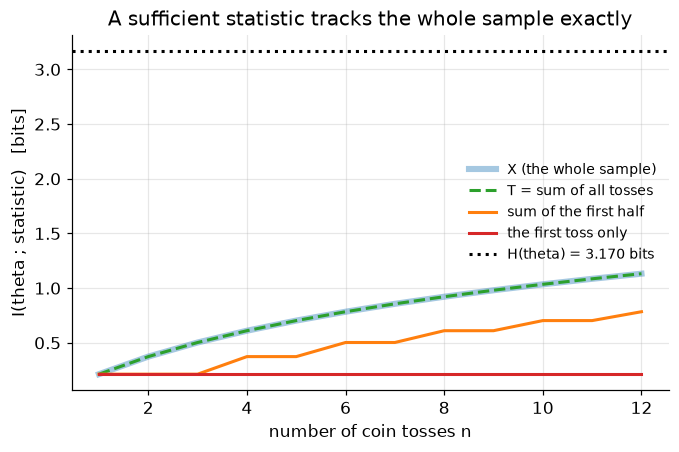

[PASS] the sufficient statistic matches the whole sample at every n


True

In [9]:
n_values = range(1, 13)
curves = {"X (the whole sample)": [], "T = sum of all tosses": [],
          "sum of the first half": [], "the first toss only": []}

for nn in n_values:
    seqs = np.array(list(product([0, 1], repeat=nn)))
    Jn = joint_theta_x(theta_grid, prior, seqs)
    curves["X (the whole sample)"].append(it.mutual_information(Jn))
    curves["T = sum of all tosses"].append(
        it.mutual_information(apply_statistic(Jn, seqs.sum(axis=1))[0]))
    curves["sum of the first half"].append(
        it.mutual_information(apply_statistic(Jn, seqs[:, :max(1, nn//2)].sum(axis=1))[0]))
    curves["the first toss only"].append(
        it.mutual_information(apply_statistic(Jn, seqs[:, 0])[0]))

styles = {"X (the whole sample)": dict(color=it.COLORS["H"], linewidth=4, alpha=0.4),
          "T = sum of all tosses": dict(color=it.COLORS["I"], linestyle="--"),
          "sum of the first half": dict(color=it.COLORS["cond"]),
          "the first toss only": dict(color=it.COLORS["D"])}

for name, values in curves.items():
    plt.plot(list(n_values), values, label=name, **styles[name])
plt.axhline(it.entropy(prior), color="black", linestyle=":",
            label=f"H(theta) = {it.entropy(prior):.3f} bits")
plt.xlabel("number of coin tosses n")
plt.ylabel("I(theta ; statistic)   [bits]")
plt.title("A sufficient statistic tracks the whole sample exactly")
plt.legend(fontsize=9)
plt.show()

it.check("the sufficient statistic matches the whole sample at every n",
         np.allclose(curves["X (the whole sample)"], curves["T = sum of all tosses"]))

## 7.7 Summary

For every statistic $T$ of the data,

$$I(\theta; T(X)) \le I(\theta; X),$$

because $\theta \to X \to T(X)$ is a Markov chain. **Sufficiency is precisely
the case of equality.** A sufficient statistic is a lossless compression of
the data as far as $\theta$ is concerned; the minimal sufficient statistic is
the shortest such compression.

This is the whole content of Section 2.9: a statistical idea that predates
information theory turns out to be a statement about the data-processing
inequality.
